# 📊 Complete Machine Learning Visualizations Catalog

This notebook provides the exact syntax and working implementations for all standard Machine Learning visualization categories:

1. **Confusion Matrix** (`sns.heatmap` & `ConfusionMatrixDisplay`)
2. **ROC Curve** (`roc_curve` with `plt.plot` & `RocCurveDisplay`)
3. **Precision-Recall Curve** (`PrecisionRecallDisplay`)
4. **Regression & Scatter** (`sns.regplot` & `sns.scatterplot`)
5. **Feature Importance** (`plt.bar` & `plt.barh`)
6. **Subplots Grid** (`fig, axes = plt.subplots`)
7. **Histograms & Boxplots** (`plt.hist`, `sns.histplot`, `sns.boxplot`)
8. **Classification / Clustering Scatter** (`sns.scatterplot` with 2D feature slices)
9. **Learning / Validation Curves** (`learning_curve` & `validation_curve`)
10. **Dimensionality Reduction** (`PCA` & `t-SNE` scatter plots)
11. **Error / Residual Analysis** (`residuals = y_true - y_pred`, parity line, `sns.kdeplot`)
12. **Training Dynamics** (`loss` & `val_loss` progression curves)


## 0. Setup and Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.model_selection import train_test_split, learning_curve, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, RocCurveDisplay,
    precision_recall_curve, PrecisionRecallDisplay
)

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)

# --- Prepare Classification Data (Breast Cancer) ---
cancer = load_breast_cancer(as_frame=True)
X_c, y_c = cancer.data, cancer.target
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_c, y_c, test_size=0.25, random_state=42, stratify=y_c)

scaler_c = StandardScaler()
X_tr_c_scaled = scaler_c.fit_transform(X_train_c)
X_te_c_scaled = scaler_c.transform(X_test_c)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_tr_c_scaled, y_train_c)
y_true = y_test_c
y_pred = clf.predict(X_te_c_scaled)
y_score = clf.predict_proba(X_te_c_scaled)[:, 1]

# --- Prepare Regression Data (Diabetes) ---
diabetes = load_diabetes(as_frame=True)
X_r, y_r = diabetes.data, diabetes.target
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_r, y_r, test_size=0.25, random_state=42)

reg = LinearRegression().fit(X_train_r, y_train_r)
y_true_reg = y_test_r
y_pred_reg = reg.predict(X_test_r)

print("✓ Datasets, classification models, and regression models loaded successfully.")

✓ Datasets, classification models, and regression models loaded successfully.


---
## % ================= Confusion Matrix =================
Two standard syntax approaches:
1. `sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', ...)`
2. `ConfusionMatrixDisplay.from_predictions(y_true, y_pred)`


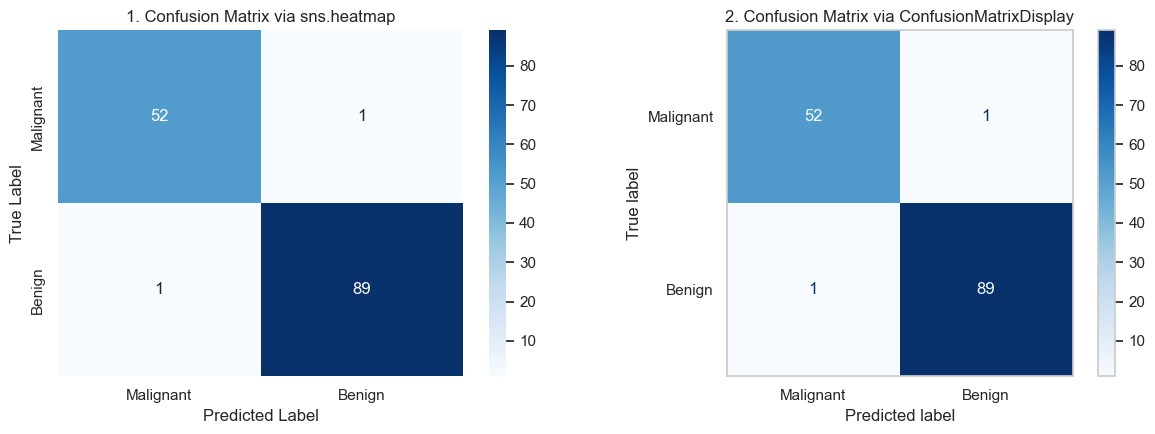

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Method 1: Using Seaborn Heatmap
conf_matrix = confusion_matrix(y_true, y_pred)
labels = ['Malignant', 'Benign']

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)
axes[0].set_title("1. Confusion Matrix via sns.heatmap")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Method 2: Using Scikit-Learn ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=labels,
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("2. Confusion Matrix via ConfusionMatrixDisplay")
axes[1].grid(False)

plt.tight_layout()
plt.show()

---
## % ================= ROC Curve =================
Two standard syntax approaches:
1. `roc_curve` with `plt.plot(fpr, tpr)` and diagonal reference `plt.plot([0, 1], [0, 1], linestyle="--")`
2. `RocCurveDisplay.from_predictions(y_true, y_score)`


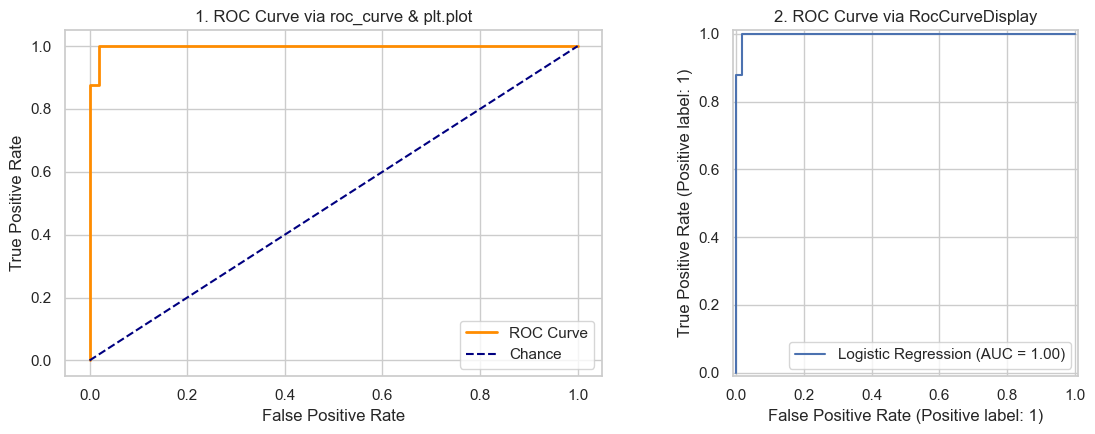

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Method 1: Manual Calculation with roc_curve & plt.plot
fpr, tpr, thr = roc_curve(y_true, y_score)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label="ROC Curve")
axes[0].plot([0, 1], [0, 1], linestyle="--", color='navy', label="Chance")
axes[0].set_title("1. ROC Curve via roc_curve & plt.plot")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Method 2: Using RocCurveDisplay
RocCurveDisplay.from_predictions(
    y_true,
    y_score,
    name="Logistic Regression",
    ax=axes[1]
)
axes[1].set_title("2. ROC Curve via RocCurveDisplay")

plt.tight_layout()
plt.show()

---
## % ================= Precision-Recall Curve =================
Evaluates precision against recall trade-offs across classification thresholds:
- `PrecisionRecallDisplay.from_predictions(y_true, y_score)`


<Figure size 650x450 with 0 Axes>

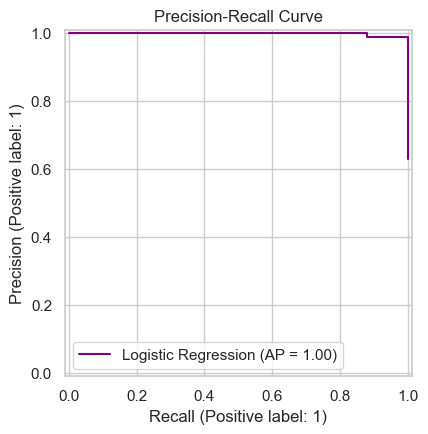

In [4]:
plt.figure(figsize=(6.5, 4.5))

PrecisionRecallDisplay.from_predictions(
    y_true,
    y_score,
    name="Logistic Regression",
    color="purple"
)
plt.title("Precision-Recall Curve")
plt.show()

---
## % ================= Regression & Scatter =================
- `sns.regplot(x=y_true, y=y_pred, ci=int_or_None)`
- `sns.scatterplot(x=x, y=y, hue=col_or_None)`


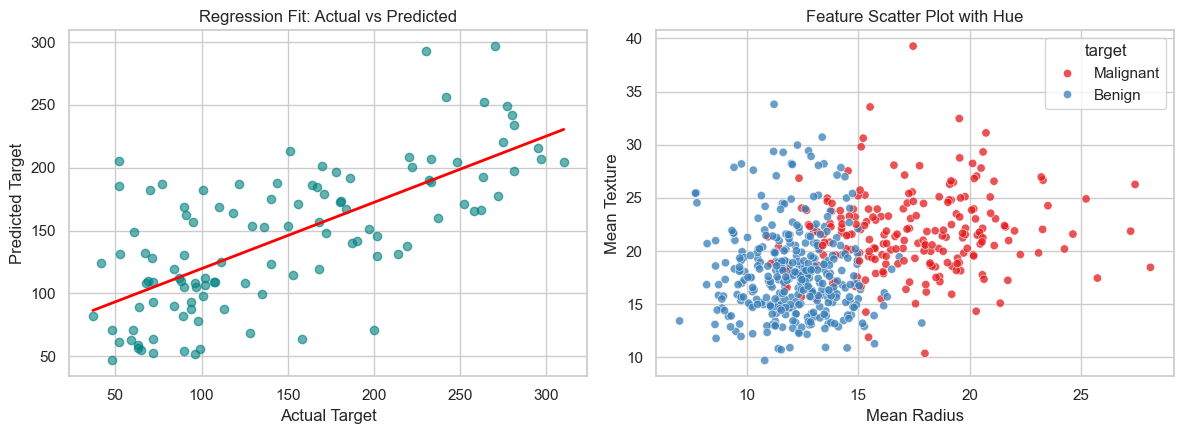

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Regression Plot (Actual vs Predicted with regression fit line)
sns.regplot(
    x=y_true_reg,
    y=y_pred_reg,
    ci=None,
    scatter_kws={'alpha': 0.6, 'color': 'teal'},
    line_kws={'color': 'red', 'lw': 2},
    ax=axes[0]
)
axes[0].set_title("Regression Fit: Actual vs Predicted")
axes[0].set_xlabel("Actual Target")
axes[0].set_ylabel("Predicted Target")

# 2. Scatter Plot with Categorical Hue
sns.scatterplot(
    x=cancer.frame['mean radius'],
    y=cancer.frame['mean texture'],
    hue=cancer.frame['target'].map({0: 'Malignant', 1: 'Benign'}),
    palette="Set1",
    alpha=0.75,
    ax=axes[1]
)
axes[1].set_title("Feature Scatter Plot with Hue")
axes[1].set_xlabel("Mean Radius")
axes[1].set_ylabel("Mean Texture")

plt.tight_layout()
plt.show()

---
## % ================= Feature Importance =================
- `plt.bar(feature_names, coef_or_importance)` (Vertical bar plot)
- `plt.barh(feature_names, importance)` (Horizontal bar plot)


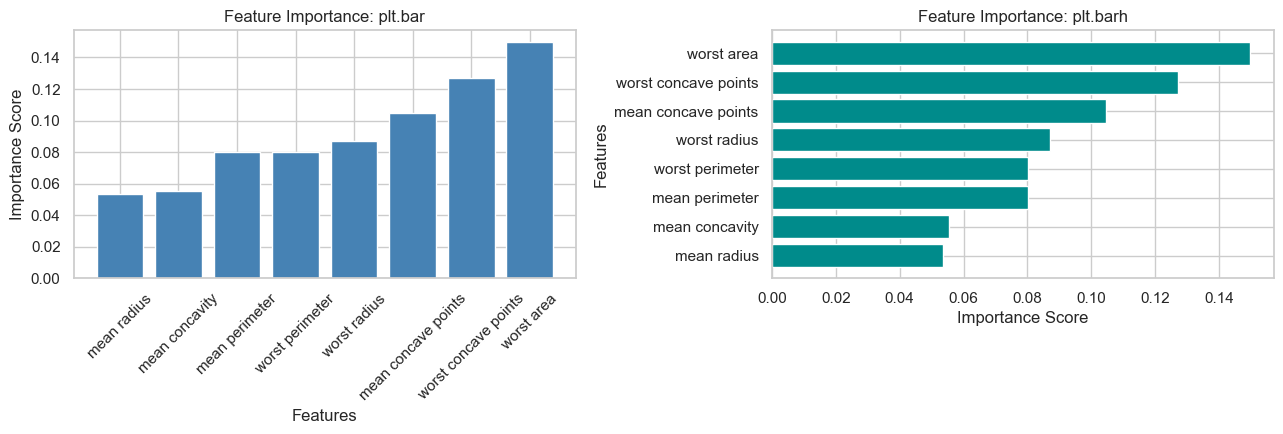

In [6]:
# Train Random Forest to obtain feature importances
rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tr_c_scaled, y_train_c)
importances = rf_model.feature_importances_
top_indices = np.argsort(importances)[-8:]  # Top 8 features

feature_names = X_c.columns[top_indices]
importance_values = importances[top_indices]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Vertical Bar Plot: plt.bar
axes[0].bar(feature_names, importance_values, color="steelblue")
axes[0].set_title("Feature Importance: plt.bar")
axes[0].set_xlabel("Features")
axes[0].set_ylabel("Importance Score")
axes[0].tick_params(axis='x', rotation=45)

# Horizontal Bar Plot: plt.barh
axes[1].barh(feature_names, importance_values, color="darkcyan")
axes[1].set_title("Feature Importance: plt.barh")
axes[1].set_xlabel("Importance Score")
axes[1].set_ylabel("Features")

plt.tight_layout()
plt.show()

---
## % ================= Subplots =================
Configurable multi-panel layout:
- `fig, axes = plt.subplots(nrows=int, ncols=int, figsize=(width, height_per_row * nrows))`


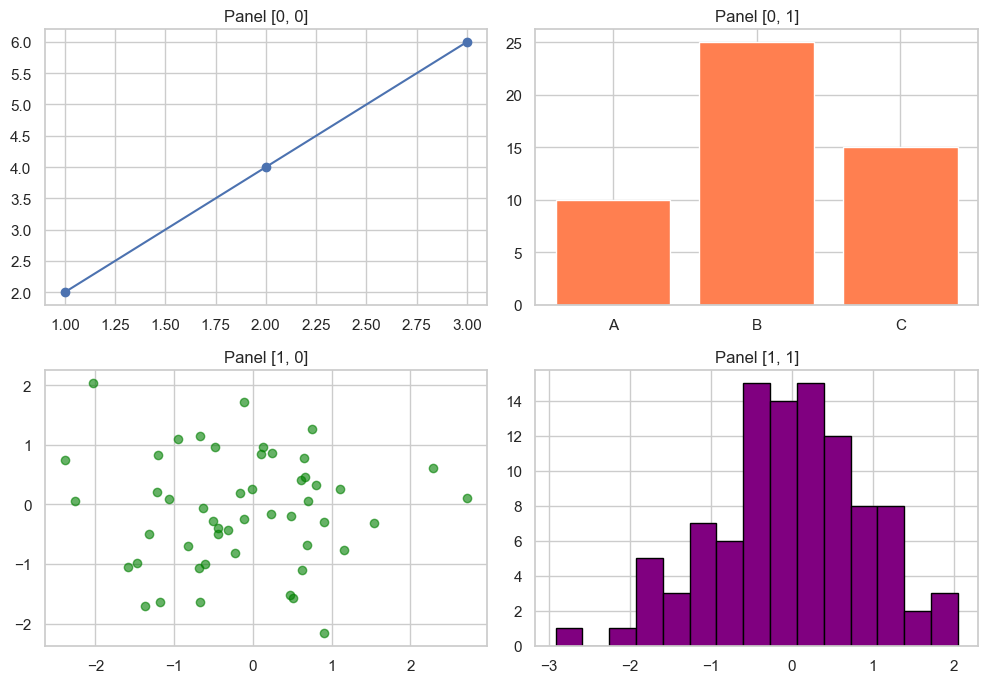

In [7]:
nrows, ncols = 2, 2
width, height_per_row = 10, 3.5

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(width, height_per_row * nrows)
)

axes[0, 0].plot([1, 2, 3], [2, 4, 6], 'b-o')
axes[0, 0].set_title("Panel [0, 0]")

axes[0, 1].bar(['A', 'B', 'C'], [10, 25, 15], color='coral')
axes[0, 1].set_title("Panel [0, 1]")

axes[1, 0].scatter(np.random.randn(50), np.random.randn(50), color='green', alpha=0.6)
axes[1, 0].set_title("Panel [1, 0]")

axes[1, 1].hist(np.random.normal(0, 1, 100), bins=15, color='purple', edgecolor='black')
axes[1, 1].set_title("Panel [1, 1]")

plt.tight_layout()
plt.show()

---
## % ================= Histograms & Boxplots =================
- `plt.hist(data, bins=int, color="color", edgecolor="color")`
- `sns.histplot(data=DataFrame, x=column, bins=int, color="color", edgecolor="color", ax=axes[i])`
- `sns.boxplot(data=DataFrame, x=column, ax=axes[i])`


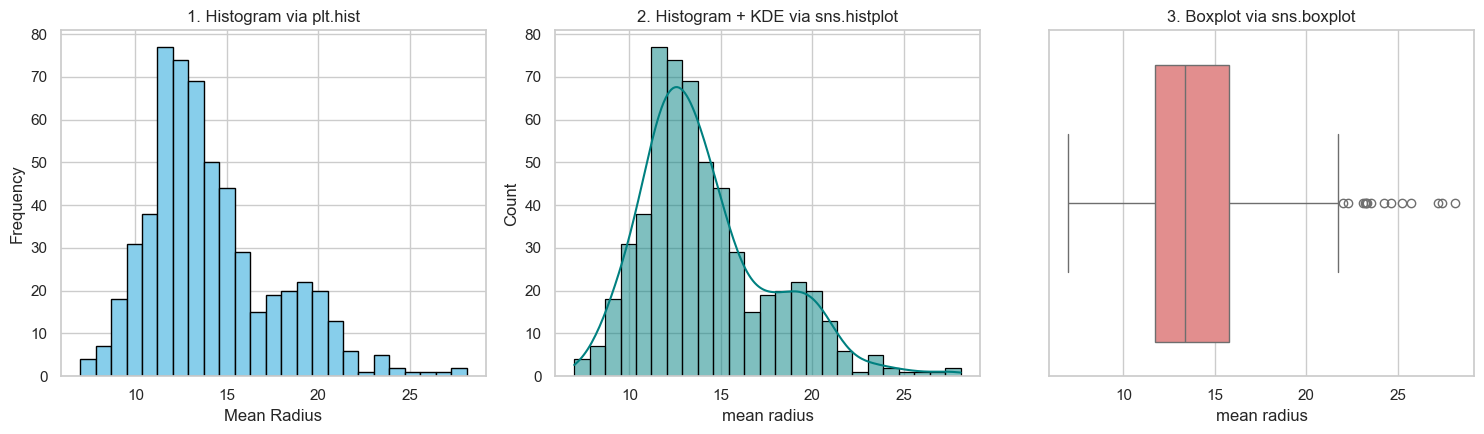

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Matplotlib Histogram: plt.hist
axes[0].hist(
    cancer.frame['mean radius'],
    bins=25,
    color="skyblue",
    edgecolor="black"
)
axes[0].set_title("1. Histogram via plt.hist")
axes[0].set_xlabel("Mean Radius")
axes[0].set_ylabel("Frequency")

# 2. Seaborn Histogram: sns.histplot
sns.histplot(
    data=cancer.frame,
    x='mean radius',
    bins=25,
    color="teal",
    edgecolor="black",
    kde=True,
    ax=axes[1]
)
axes[1].set_title("2. Histogram + KDE via sns.histplot")

# 3. Seaborn Boxplot: sns.boxplot
sns.boxplot(
    data=cancer.frame,
    x='mean radius',
    color="lightcoral",
    ax=axes[2]
)
axes[2].set_title("3. Boxplot via sns.boxplot")

plt.tight_layout()
plt.show()

---
## % ================= Classification / Clustering Scatter =================
- `sns.scatterplot(x=1d_X, y=1d_Y, hue=labels, palette="deep/tab10/coolwarm", legend="full/brief/False", s=int)`
- `sns.scatterplot(x=X[:,0], y=X[:,1], hue=labels)`


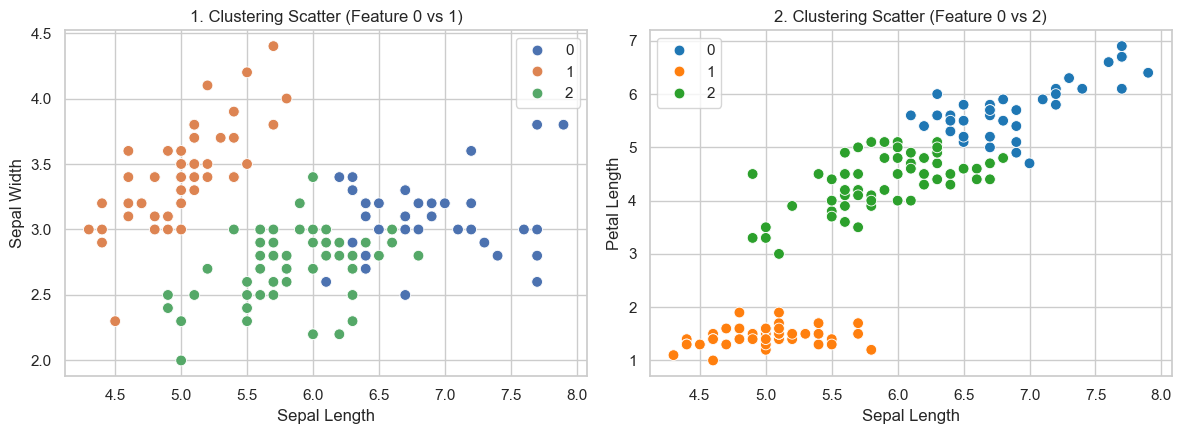

In [9]:
# Load Iris and perform K-Means Clustering
iris = load_iris()
X_iris = iris.data
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto').fit(X_iris)
cluster_labels = kmeans.labels_

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Scatter using explicit 1D feature arrays and hue
sns.scatterplot(
    x=X_iris[:, 0],
    y=X_iris[:, 1],
    hue=cluster_labels,
    palette="deep",
    legend="full",
    s=60,
    ax=axes[0]
)
axes[0].set_title("1. Clustering Scatter (Feature 0 vs 1)")
axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal Width")

# 2. Scatter indexing X[:, 0] and X[:, 2] with tab10 palette
sns.scatterplot(
    x=X_iris[:, 0],
    y=X_iris[:, 2],
    hue=cluster_labels,
    palette="tab10",
    legend="brief",
    s=60,
    ax=axes[1]
)
axes[1].set_title("2. Clustering Scatter (Feature 0 vs 2)")
axes[1].set_xlabel("Sepal Length")
axes[1].set_ylabel("Petal Length")

plt.tight_layout()
plt.show()

---
## % ================= Learning / Validation Curves =================
- **Learning Curve**: Tracks training score and validation score across increasing training dataset sizes:
  - `plt.plot(train_sizes, train_scores.mean(axis=1))`
  - `plt.plot(train_sizes, val_scores.mean(axis=1))`
- **Validation Curve**: Tracks performance across changing hyperparameter ranges:
  - `plt.plot(param_range, train_scores.mean(axis=1))`
  - `plt.plot(param_range, val_scores.mean(axis=1))`


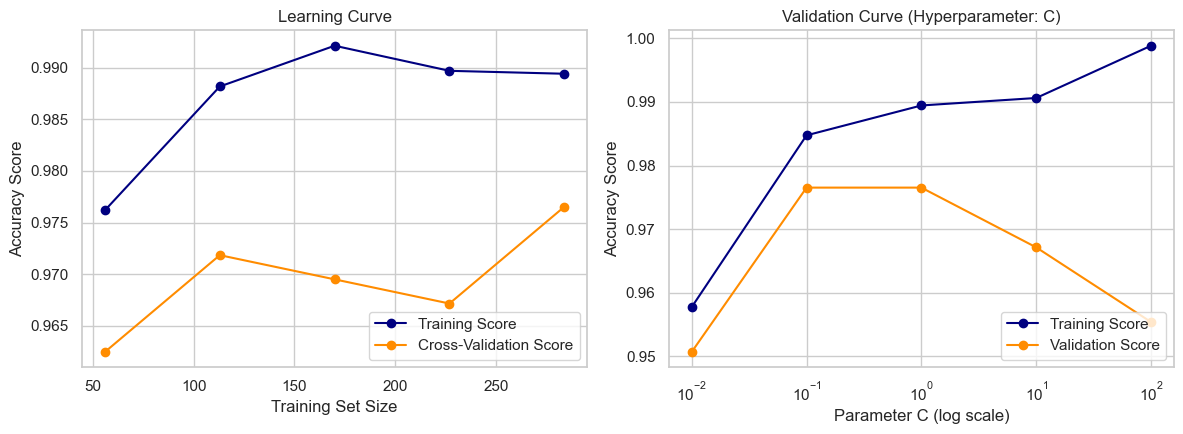

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Learning Curve (Dataset Size vs Score)
train_sizes, train_scores_lc, val_scores_lc = learning_curve(
    LogisticRegression(max_iter=1000), X_tr_c_scaled, y_train_c,
    train_sizes=np.linspace(0.2, 1.0, 5), cv=3, scoring='accuracy'
)

axes[0].plot(train_sizes, train_scores_lc.mean(axis=1), 'o-', color='navy', label="Training Score")
axes[0].plot(train_sizes, val_scores_lc.mean(axis=1), 'o-', color='darkorange', label="Cross-Validation Score")
axes[0].set_title("Learning Curve")
axes[0].set_xlabel("Training Set Size")
axes[0].set_ylabel("Accuracy Score")
axes[0].legend(loc="lower right")

# 2. Validation Curve (Hyperparameter C vs Score)
param_range = np.logspace(-2, 2, 5)
train_scores_vc, val_scores_vc = validation_curve(
    LogisticRegression(max_iter=1000), X_tr_c_scaled, y_train_c,
    param_name="C", param_range=param_range, cv=3, scoring='accuracy'
)

axes[1].plot(param_range, train_scores_vc.mean(axis=1), 'o-', color='navy', label="Training Score")
axes[1].plot(param_range, val_scores_vc.mean(axis=1), 'o-', color='darkorange', label="Validation Score")
axes[1].set_xscale("log")
axes[1].set_title("Validation Curve (Hyperparameter: C)")
axes[1].set_xlabel("Parameter C (log scale)")
axes[1].set_ylabel("Accuracy Score")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

---
## % ================= Dimensionality Reduction =================
- `plt.scatter(X_pca[:,0], X_pca[:,1], c=y)`
- `plt.scatter(X_tsne[:,0], X_tsne[:,1], c=y)`


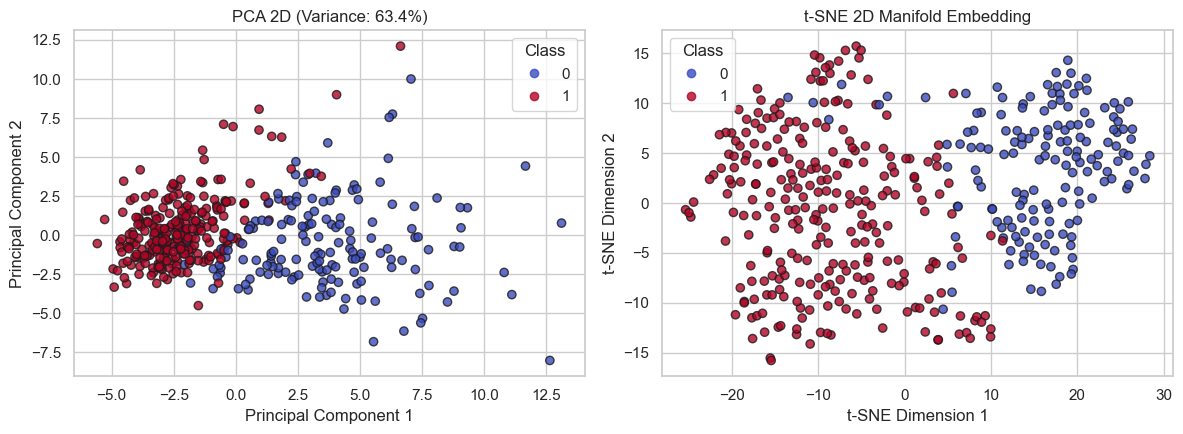

In [11]:
# Compute PCA and t-SNE
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_tr_c_scaled)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_tr_c_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. PCA 2D Scatter
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_train_c, cmap="coolwarm", alpha=0.8, edgecolor='k')
axes[0].set_title(f"PCA 2D (Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend(*scatter1.legend_elements(), title="Class")

# 2. t-SNE 2D Scatter
scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_train_c, cmap="coolwarm", alpha=0.8, edgecolor='k')
axes[1].set_title("t-SNE 2D Manifold Embedding")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")
axes[1].legend(*scatter2.legend_elements(), title="Class")

plt.tight_layout()
plt.show()

---
## % ================= Error / Residual Analysis =================
- `residuals = y_true - y_pred`
- `plt.scatter(y_pred, residuals)`
- `plt.axhline(0, color="color", linestyle="style")`
- `sns.kdeplot(residuals)`
- `plt.plot(y_true, y_pred, 'o')` with 45-degree parity line:
  `plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)])`


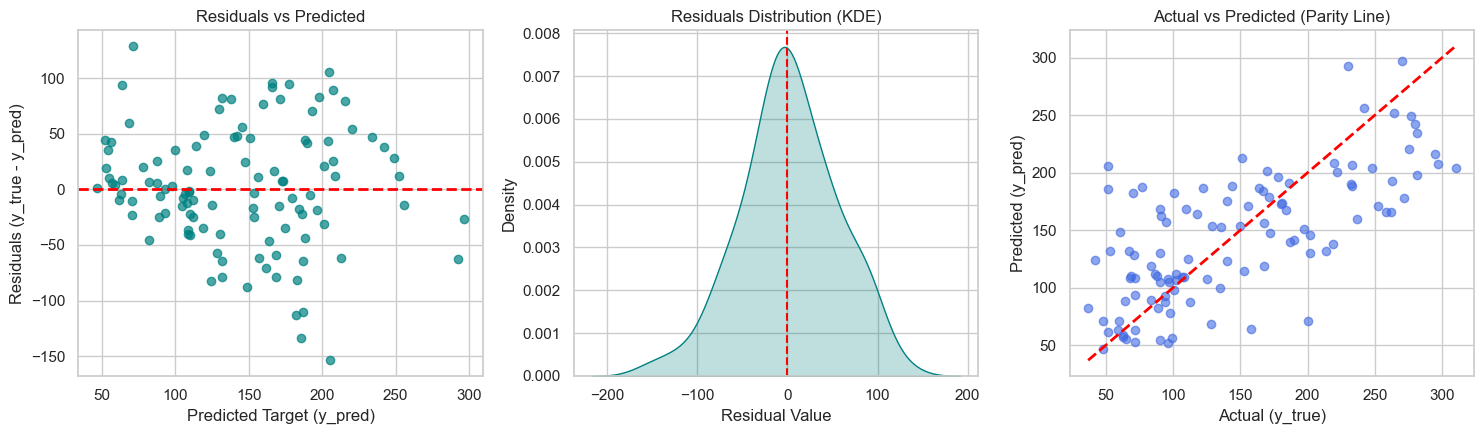

In [12]:
# Compute residuals
residuals = y_true_reg - y_pred_reg

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Residuals vs Predicted with axhline(0)
axes[0].scatter(y_pred_reg, residuals, color='teal', alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--", lw=2)
axes[0].set_title("Residuals vs Predicted")
axes[0].set_xlabel("Predicted Target (y_pred)")
axes[0].set_ylabel("Residuals (y_true - y_pred)")

# 2. Residual Distribution via KDE Plot
sns.kdeplot(residuals, fill=True, color='teal', ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--", lw=1.5)
axes[1].set_title("Residuals Distribution (KDE)")
axes[1].set_xlabel("Residual Value")

# 3. Parity Plot: Actual vs Predicted with 45° Reference Line
axes[2].plot(y_true_reg, y_pred_reg, 'o', color='royalblue', alpha=0.6)
min_val = min(y_true_reg.min(), y_pred_reg.min())
max_val = max(y_true_reg.max(), y_pred_reg.max())
axes[2].plot([min_val, max_val], [min_val, max_val], color='red', linestyle="--", lw=2)
axes[2].set_title("Actual vs Predicted (Parity Line)")
axes[2].set_xlabel("Actual (y_true)")
axes[2].set_ylabel("Predicted (y_pred)")

plt.tight_layout()
plt.show()

---
## % ================= Training Dynamics =================
- `plt.plot(history.history["loss"])`
- `plt.plot(history.history["val_loss"])`


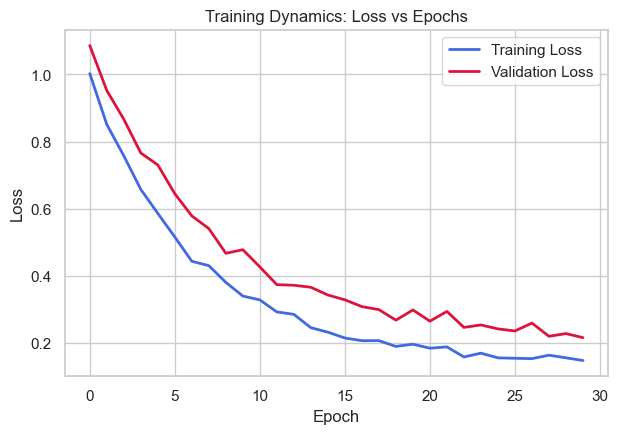

In [13]:
# Simulated history object mimicking Keras / Deep Learning model training
epochs = np.arange(1, 31)
loss = np.exp(-epochs / 6.0) + 0.15 + np.random.normal(0, 0.01, size=len(epochs))
val_loss = np.exp(-epochs / 7.0) + 0.22 + np.random.normal(0, 0.015, size=len(epochs))

history = {
    "history": {
        "loss": loss,
        "val_loss": val_loss
    }
}

plt.figure(figsize=(7, 4.5))
plt.plot(history["history"]["loss"], label="Training Loss", color="royalblue", lw=2)
plt.plot(history["history"]["val_loss"], label="Validation Loss", color="crimson", lw=2)
plt.title("Training Dynamics: Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.show()